# **A3-ATMOSFERİK DÜZELTMELER**

### **İş akışı özet:**

- **Veriler Satellites.csv olarak okunup sat1'den sat9'a kadar listelere ayrı ayrı kaydedildi. 1-VERİLERİ OKUMA bitti.<span style="color:red">Multipath hatası olmadan yapıldı tüm hesaplar</span>**
- **Uydu jeodezisi kitabı 7.139'uncu formül iyonosfer gecikmesini modellemek için kullanıldı. Farklı taşıyıcı frekanslarından iyonosferik gecikme hesaplandı ve verilere direkt uygulandı. 2-İYONOSFER GECİKMESİ HESABI bitti.**
- **Saastamoinen formülü GPS teorisi kitabı 5.98'den alındı. Meteoroloji verileri 14m dosyasından alınıp, işlendi. 3-TROPOSFER VE METEOROLOJİ VERİLERİ İŞLEME bitti.**
- **Yaklaşık alıcı koordinatları 14o dosyasından alındı. Uydu koordinatları sp3<span style="color:red">(14n üzerinden hesapmı yapılmalı?)</span> dosyasından alındı, verilen epoktaki 31 uydunun sp3 satırı kaydedildi.**
- **Alıcı ve uydu koordinatları arası mesafeler hesaplandı.**
- **E,N,U koordinatlarına dönüp E hesabı yapıldı. Sonra 31 uydu için farklı E değerleri çıkınca gözlem anında görülen 9 uydu seçildi ve onların E değeri alındı. 4-E UYDU YÜKSELİM AÇISI HESABI**
- **H  ortometrik yükseklik yaklaşık konumdan Ng= 36.8 kabulu ile hesaplandı ve B değeri ile &R değeri tablolardan verilen değerler için bulunup yerine konuldu. Troposferik gecikme hesaplandı ve gözlemlere uygulandı. Sonuçlar Satellites2.csv olarak kaydedildi. 5-DÜZELTMELER VE SONUÇ bitmedi !!!!!!!!!!!!!!!!!!!!!**

## **1-VERİLERİ OKUMA**

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
df = pd.read_csv("../data/satellites.csv")
df # pandas csv okumak için

,Satellite,C1,P1,L1,D1,P2,L2,D2
0,G19,2.118906e+07,2.118906e+07,-2.342237e+07,-1624.826,2.118906e+07,-1.823279e+07,-1266.095
1,G27,2.252061e+07,2.252061e+07,-1.626506e+07,-3131.943,2.252062e+07,-1.266448e+07,-2440.473
2,G11,2.096043e+07,2.096043e+07,-2.023690e+07,2125.069,2.096044e+07,-1.575303e+07,1655.895
3,G20,2.459961e+07,2.459961e+07,-4.001554e+06,3287.044,2.459962e+07,-2.858091e+06,2561.330
4,G22,2.234385e+07,2.234385e+07,-1.900831e+07,-2218.107,2.234386e+07,-1.478600e+07,-1728.398
5,G14,2.137030e+07,2.137029e+07,-1.900141e+07,-529.566,2.137030e+07,-1.455393e+07,-412.656
6,G32,2.112843e+07,2.112843e+07,-1.989570e+07,1824.349,2.112843e+07,-1.548879e+07,1421.562
7,G01,2.255605e+07,2.255605e+07,-1.514390e+07,2922.988,2.255606e+07,-1.177665e+07,2277.661
8,G31,0.000000e+00,2.520929e+07,-8.747164e+04,3119.319,2.522058e+07,-3.090521e+03,2429.440


In [3]:
# csvden yine listeye dönüştür sat1 sat2 ...
for i in range(9):
    globals()[f"sat{i+1}"] = ([str(df.iloc[i, 0])] + [float(x) for x in df.iloc[i, 1:]])
    print(globals()[f"sat{i+1}"])

['G19', 21189058.919, 21189058.224, -23422371.335, -1624.826, 21189062.761, -18232789.099, -1266.095]
['G27', 22520607.109, 22520607.184, -16265062.308, -3131.943, 22520615.61, -12664483.164, -2440.473]
['G11', 20960433.392, 20960432.985, -20236898.563, 2125.069, 20960438.054, -15753030.25, 1655.895]
['G20', 24599610.601, 24599611.385, -4001554.056, 3287.044, 24599619.779, -2858090.765, 2561.33]
['G22', 22343853.992, 22343853.46, -19008308.324, -2218.107, 22343856.607, -14786004.908, -1728.398]
['G14', 21370295.018, 21370294.498, -19001406.309, -529.566, 21370299.873, -14553929.347, -412.656]
['G32', 21128427.864, 21128427.325, -19895704.4, 1824.349, 21128433.745, -15488787.194, 1421.562]
['G01', 22556048.986, 22556050.48, -15143902.884, 2922.988, 22556058.525, -11776649.861, 2277.661]
['G31', 0.0, 25209285.799, -87471.641, 3119.319, 25220575.865, -3090.521, 2429.44]


## **2-İYONOSFER GECİKMESİ HESABI**

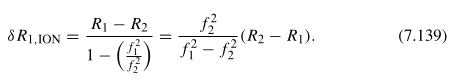

- **Satellite Geodesy kitabı 7.139uncu formül**
- **&R1,ION = P1 kod gözlemine uygulanacak iyonosferik gecikme düzeltmesi.**
- **R1 = P1**
- **R2 = P2**
- **f1 = GPS L1 sinyalinin taşıyıcı frekansı.**
- **f2 = GPS L2 sinyalinin taşıyıcı frekansı.**
- **&R1,ION düzeltmesi P1 için uygulandıktan sonra P2ye uygulanması için f1ler f2, f2ler f1 olur ve P1 ile P2 ler yer değişir formülde.**

In [4]:
# frekanslar Hz 
f1 = 1575.42 * 1000000
f2 = 1227.60 * 1000000
iono_correction_list = []

In [6]:
for i in range(9):
    sat_P1 = globals()[f"sat{i+1}"][2] #P1
    sat_P2 = globals()[f"sat{i+1}"][5] #P2
    iono_correction_p1 = (f2*f2/(f1*f1-f2*f2)) * (sat_P2-sat_P1)
    iono_correction_p2 = (f1*f1/(f2*f2-f1*f1)) * (sat_P1-sat_P2)
    iono_correction_list.append(iono_correction_p1)
    iono_correction_list.append(iono_correction_p2)
    print(iono_correction_p1,iono_correction_p2)

7.012966939337318 11.549966939814155
13.024302274180666 21.450302273226992
7.835294120733499 12.904294122730255
12.974838982866066 21.36883898039247
4.8644053239892 8.01140532386999
8.308286818376986 13.683286818376986
9.923572351411465 16.343572353199605
12.435379988418315 20.480379986481164
17451.368656075017 28741.43465607466


In [7]:
sat1[2], sat1[5]

(21189058.224, 21189062.761)

In [8]:
# iyonosferik gecikmelerin sat listelere uygulanması
for i in range(9):
    sat_P1 = globals()[f"sat{i+1}"][2] #P1
    sat_P2 = globals()[f"sat{i+1}"][5] #P2
    globals()[f"sat{i+1}"][2] = sat_P1 - iono_correction_list[i*2]
    globals()[f"sat{i+1}"][5] = sat_P2 - iono_correction_list[i*2+1]

In [9]:
sat1[2], sat1[5]

(21189051.21103306, 21189051.21103306)

## **3-TROPOSFER VE METEOROLOJİ VERİLERİ İŞLEME**

- **Troposfer gecikmesi her frekans için aynıdır birebir, iyonosfer aksine çift frekansla modellenemez.**
- **Saastamoinen veya Hopfield iki farklı troposfer modelidir.**

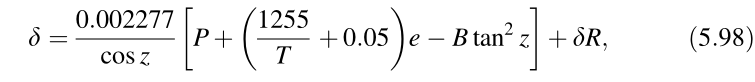

- **GPS Theory kitabında 5.98inci formül.**
- **Burada saastamoinen üzerinden hesap yapıldı.**
- **Meteoroloji dosyalarından basınç, sıcaklık, su buharı kısmi basıncı alındı.**
- **P = Pressure = basınç, T = temperature = sıcaklık (kelvine çevrildi), e = water pressure = su buharı kısmi basıncı (bağıl nemden hesaplandı)**
- **Navigasyon dosyası üzerinden broadcast ephemeristen ve yakalşık nokta koordinatlarından E uydu yükselim açısı hesaplandı.**


In [10]:
#14m meteoroloji dosyası veri satırı =  14  8 28 17 15 32  999.8   25.0   78.5
P = 999.8
T_C = 25
T_K = T_C+273.15 #kelvin
RH = 78.5

In [11]:
# RH = relative humidity hava yüzde ne kadar nemli, e = havadaki su buharının uyguladığı basınç
def vapor_pressure(T, RH):
    e_s = 6.112 * np.exp(17.67 * T / (T + 243.5))
    return (RH / 100) * e_s

e = vapor_pressure(T_C, RH)

In [12]:
print("Basınç:",P)
print("Sıcaklık:", T_K, "K")
print("Su buharı kısmi basıncı:", e, "hPa")

Basınç: 999.8
Sıcaklık: 298.15 K
Su buharı kısmi basıncı: 24.864321074070187 hPa


## **4-E UYDU YÜKSELİM AÇISI HESABI**

- **Yaklaşık alıcı koordinatları direkt kopyalanıp yapıştırıldı gözlem dosyasından.**
- **Sonra uydu konumları sp3 dosyasından alınıp işlendi.**
- **Yaklaşık alıcı ve uydu mesafeleri hesaplandı.**

In [13]:
#   4208830.3061  2334850.2992  4171267.2489                  APPROX POSITION XYZ
X_approx = 4208830.3061
Y_approx = 2334850.2992
Z_approx = 4171267.2489

In [14]:
# başlangıç ile bitiş satırı arası verileri toplar, satırın tamamını girdi olarak yaz, boşluklar ile beraber kopyala
def get_data(file_path, start_line, end_line):
    data = []
    collecting = False

    with open(file_path, "r") as f:
        for line in f:
            if line.rstrip() == start_line:
                collecting = True

            if line.rstrip() == end_line:
                break

            if collecting:
                data.append(line.rstrip())

    return data

In [15]:
data_dir = Path("../data")
sp3_file = data_dir / "igs18074.sp3"

In [16]:
data = get_data(sp3_file,
               "*  2014  8 28 17 15  0.00000000",
               "*  2014  8 28 17 30  0.00000000")
data = data[1:]

In [17]:
data[:5]

['PG01  13476.921598 -10426.955243  20291.904644     20.349088  4  6  7 120',
 'PG02 -13550.313835 -15991.021351 -16281.321964    515.186695  7  5  5 122',
 'PG04   7308.999939 -21942.314164  12476.840846     -0.280439  6  9  4 131',
 'PG05 -18419.851511  -3796.077731 -18858.852840   -345.105473  3  6  4 110',
 'PG06  -7035.751316 -24544.047305  -7350.758926     -5.073708  6  8  7  84']

In [18]:
data[:1]

['PG01  13476.921598 -10426.955243  20291.904644     20.349088  4  6  7 120']

In [19]:
# uydu koordinat listesi sp3ten verilen epokta lındıktan sonra listeye kaydedildi.
# listeler iç içe sat_xyz_list[0] 0ıncı uydunu satırındaki bütün bilgileri içeren başka bir liste
sat_xyz_list = []
for i in range(len(data)):
    x = data[i].split()
    sat_xyz_list.append(x)

In [20]:
sat_xyz_list[0]

['PG01',
 '13476.921598',
 '-10426.955243',
 '20291.904644',
 '20.349088',
 '4',
 '6',
 '7',
 '120']

In [21]:
sat_xyz_list[0][0]

'PG01'

In [22]:
# uydu koordinatları metre biriminde float veri tipine çevrildi.
for i in range(len(sat_xyz_list)):
    sat_xyz_list[i][1] = float(sat_xyz_list[i][1])*1000
    sat_xyz_list[i][2] = float(sat_xyz_list[i][2])*1000
    sat_xyz_list[i][3] = float(sat_xyz_list[i][3])*1000

In [23]:
sat_xyz_list[0]

['PG01',
 13476921.598000001,
 -10426955.243,
 20291904.643999998,
 '20.349088',
 '4',
 '6',
 '7',
 '120']

In [24]:
# her uydu için yaklaşık xyz ile uydu xyz arası mesafe hesaplanıp kaydedildi.
sat_approx_dist_list = []
for i in range(len(sat_xyz_list)):
    sat_X = sat_xyz_list[i][1]
    sat_Y = sat_xyz_list[i][2]
    sat_Z = sat_xyz_list[i][3]
    d_x = sat_X - X_approx
    d_y = sat_Y - Y_approx
    d_z = sat_Z - Z_approx
    sat_approx_dist_list.append(d_x)
    sat_approx_dist_list.append(d_y)
    sat_approx_dist_list.append(d_z)

In [25]:
sat_approx_dist_list[:3]

[9268091.291900001, -12761805.542200001, 16120637.395099998]

In [26]:
# WGS84 elipsoidi bilgileri
a = 6378137.0
f = 1 / 298.257223563
e2 = 2*f - f**2

In [27]:
# Yaklaşık alıcı koordinatları lat long dönüş
# enlem hesabı
lat_rad = np.arctan2(
    Z_approx,
    np.sqrt(X_approx**2 + Y_approx**2) * (1 - e2)
)
# boylam hesabı
lon_rad = np.arctan2(Y_approx, X_approx)

In [28]:
# Radyandan dereceye çevir
lat_deg = np.degrees(lat_rad)
lon_deg = np.degrees(lon_rad)

In [29]:
lat_deg,lon_deg

(np.float64(41.10445193840972), np.float64(29.019340261978453))

- **NOT:Tüm uydular hesaplandı yanlışlıkla, ufukta belli derece üstü uydular hesaplanmalıydı epokta 9 uydu ölçülmüş. O yüzden hesaplar arasından gözlenen 9 uydu seçildi. Sonradan uydu isimlerinde silinen P ler vs eklendi.**

In [30]:
# Easting = -sin boylam d_x + cos boylam d_y
# Northing = -sin enlem cos boylam d_x - sin enlem sin boylam d_y + cos enlem d_z
# U = cos enlem cos boylam d_x + cos enlem sin boylam d_y + sin enlem d_z
elevation_deg_list = []
for i in range(31):
    sat_name = sat_xyz_list[i][0]
    d_x = sat_approx_dist_list[3*i]
    d_y = sat_approx_dist_list[3*i+1]
    d_z = sat_approx_dist_list[3*i+2]
    Easting = -np.sin(lon_rad)*d_x + np.cos(lon_rad)*d_y
    #print(i,"easting----------")
    #print(Easting)
    Northing = -np.sin(lat_rad)*np.cos(lon_rad) * d_x - np.sin(lat_rad)*np.sin(lon_rad)*d_y + np.cos(lat_rad)*d_z
    #print(i,"northing----------")
    #print(Northing)
    Up = np.cos(lat_rad)*np.cos(lon_rad)*d_x + np.cos(lat_rad)*np.sin(lon_rad)*d_y + np.sin(lat_rad)*d_z
    #print(i,"Up----------")
    #print(Up)   
    elevation_rad = np.arctan2(Up, np.sqrt(Easting**2+Northing**2))
    elevation_deg = np.degrees(elevation_rad)
    #print(i,"E----------")
    #print(elevation_deg)
    elevation_deg_list.append(sat_name)
    elevation_deg_list.append(elevation_deg)

In [31]:
elevation_deg_list[:4]

['PG01', np.float64(32.26705926927803), 'PG02', np.float64(-76.85390388707621)]

In [32]:
Satellites = df["Satellite"].tolist()
Satellites

['G19', 'G27', 'G11', 'G20', 'G22', 'G14', 'G32', 'G01', 'G31']

In [33]:
# put p on sat names for easy loop
for i in range(len(Satellites)):
    Satellites[i] = "P" + Satellites[i]

In [34]:
elevation_deg_list_at_epoch = []
for i in range(len(elevation_deg_list)):
    for name in Satellites:
        if elevation_deg_list[i] == name:
            elevation_deg_list_at_epoch.append(name)
            elevation_deg_list_at_epoch.append(elevation_deg_list[i+1])

In [35]:
# epokta görünen uyduların E değerleri
elevation_deg_list_at_epoch

['PG01',
 np.float64(32.26705926927803),
 'PG11',
 np.float64(53.39993242112078),
 'PG14',
 np.float64(53.02977429232553),
 'PG19',
 np.float64(59.48975931230301),
 'PG20',
 np.float64(9.840537832961735),
 'PG22',
 np.float64(36.454142672347515),
 'PG27',
 np.float64(33.71794870980887),
 'PG31',
 np.float64(2.3125147854654617),
 'PG32',
 np.float64(52.24965347946538)]

## **5-DÜZELTMELER VE SONUÇ <span style="color:red">None değerler 0 yapıldı yanlışmı? None alan açılar elenmeli mi? 29metreye varan hatalar normalmi?</span>**

In [36]:
# 
for _ in range(5):
    N = a / np.sqrt(1 - e2 * np.sin(lat_rad)**2) #e WGS84 için xyz lat long dönüşümünde tanımlandı
    h = np.sqrt(X_approx**2 + Y_approx**2) / np.cos(lat_rad) - N
    Ng = 36.8 
    H = h -Ng
print("Yaklaşık ortometrik yükseklik:", H, "m")

Yaklaşık ortometrik yükseklik: 110.86977657098323 m


In [37]:
# B yaklaşık 0-0.5 km arası 1.156 mbar
B = 1.156

In [38]:
zenith_deg_list_at_epoch = []
for i in range(9):
    x = 90 - elevation_deg_list_at_epoch[i*2+1]
    zenith_deg_list_at_epoch.append(x)

In [39]:
zenith_deg_list_at_epoch

[np.float64(57.73294073072197),
 np.float64(36.60006757887922),
 np.float64(36.97022570767447),
 np.float64(30.510240687696992),
 np.float64(80.15946216703827),
 np.float64(53.545857327652485),
 np.float64(56.28205129019113),
 np.float64(87.68748521453453),
 np.float64(37.75034652053462)]

In [40]:
# H = 0 km için Saastamoinen delta_R tablosu (Zenith açısı [derece] -> delta_R [metre])
delta_R_table_H0 = {
    60.00: 0.003,
    66.00: 0.006,
    70.00: 0.012,
    73.00: 0.020,
    75.00: 0.031,
    76.00: 0.039,
    77.00: 0.050,
    78.00: 0.065,
    78.50: 0.075,
    79.00: 0.087,
    79.50: 0.102,
    79.75: 0.111,
    80.00: 0.121
}

In [41]:
# None lar var bunları ne yapıcaz??????????? Sıfırladım şimdilik
delta_R_list = []

for i in range(9):
    z = zenith_deg_list_at_epoch[i]
    delta_R = None
    for angle in delta_R_table_H0:
        if z > angle:
            pass
        elif z <= angle:
            delta_R = delta_R_table_H0[angle]
            break
    delta_R_list.append(delta_R)

delta_R_list

[0.003, 0.003, 0.003, 0.003, None, 0.003, 0.003, None, 0.003]

In [42]:
for i in range(len(delta_R_list)):
    if delta_R_list[i] == None:
        delta_R_list[i] = 0

In [43]:
delta_R_list

[0.003, 0.003, 0.003, 0.003, 0, 0.003, 0.003, 0, 0.003]

In [44]:
# FORMÜL
d_trop_list = []
for i in range(9):
    z = zenith_deg_list_at_epoch[i]
    delta_R = delta_R_list[i]
    d_trop = (0.002277 / np.cos(z)) * (P + (1255 / T_K + 0.05) * e - B * (np.tan(z)**2)) + delta_R
    d_trop_list.append(d_trop)

In [45]:
#SONUÇLAR
d_trop_list

[np.float64(6.639588180172656),
 np.float64(5.520853478249667),
 np.float64(3.3754812141693904),
 np.float64(4.075633909795556),
 np.float64(29.006293800008812),
 np.float64(-2.5390790880221554),
 np.float64(2.61269871561396),
 np.float64(2.6173259998448013),
 np.float64(2.523989993842331)]

In [46]:
for i in range(9):
    sat_P1 = globals()[f"sat{i+1}"][2] #P1
    sat_P2 = globals()[f"sat{i+1}"][5] #P2
    print(sat_P1,sat_P2)
    #globals()[f"sat{i+1}"][2] = sat_P1 - d_trop_list[i]
    globals()[f"sat{i+1}"][5] = sat_P2 - d_trop_list[i]
    #print("düzeltilmiş:",globals()[f"sat{i+1}"][2],globals()[f"sat{i+1}"][5])

21189051.21103306 21189051.21103306
22520594.159697726 22520594.159697726
20960425.14970588 20960425.14970588
24599598.41016102 24599598.41016102
22343848.595594678 22343848.595594678
21370286.18971318 21370286.18971318
21128417.40142765 21128417.40142765
22556038.04462001 22556038.04462001
25191834.430343922 25191834.430343922


In [48]:
import pandas as pd

In [49]:
columns = ["Satellite", "C1", "P1", "L1", "D1", "P2", "L2", "D2"]
satellites = [sat1, sat2, sat3, sat4, sat5, sat6, sat7, sat8, sat9]

In [50]:
df = pd.DataFrame(satellites, columns=columns)
df.to_csv("../data/satellites2.csv", index=False)